<a href="https://colab.research.google.com/github/sampath0711/DEEP-LEARNING/blob/main/Skill/Skill_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch
import os
import platform

print("PYTHON VERSION:", platform.python_version())
print("PYTORCH VERSION:", torch.__version__)

print("CUDA AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

print("\nEnvironment check completed!")


PYTHON VERSION: 3.13.18
PYTORCH VERSION: 2.14.1+cpu
CUDA AVAILABLE: False
Running on CPU

Environment check completed!


In [2]:

# Create workspace

base_path = "/content/skill7_model_artifacts"

folders = [
    "architecture",
    "checkpoints",
    "onnx",
    "tensorrt",
    "reports"
]

for folder in folders:
    os.makedirs(
        os.path.join(base_path, folder),
        exist_ok=True
    )

print("Model artefact folders created successfully!")

for folder in folders:
    print(folder)


Model artefact folders created successfully!
architecture
checkpoints
onnx
tensorrt
reports


In [3]:

import torch.nn as nn
import torch.nn.functional as F

# Define CNN architecture

class TrafficCNN(nn.Module):

    def __init__(self, num_classes=14):
        super(TrafficCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(64 * 28 * 28, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Create model
model = TrafficCNN(num_classes=14)

print("Model architecture created successfully!")
print(model)


Model architecture created successfully!
TrafficCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=50176, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=14, bias=True)
)


In [4]:

import torch.optim as optim

# Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

# Create sample training data
X_train = torch.randn(100, 3, 224, 224)
y_train = torch.randint(0, 14, (100,))

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
epochs = 3

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for i in range(0, 100, 10):

        inputs = X_train[i:i+10].to(device)
        labels = y_train[i:i+10].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {total_loss/10:.4f}"
    )

print("\nModel training completed!")


Epoch [1/3], Loss: 3.6894
Epoch [2/3], Loss: 2.6145
Epoch [3/3], Loss: 2.5588

Model training completed!


In [5]:

# Save model checkpoint

checkpoint = {
    "epoch": 3,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "loss": loss.item()
}

checkpoint_path = os.path.join(
    base_path,
    "checkpoints",
    "traffic_cnn_checkpoint.pth"
)

torch.save(checkpoint, checkpoint_path)

print("Model checkpoint saved successfully!")
print("Checkpoint location:", checkpoint_path)
print("File size:", round(os.path.getsize(checkpoint_path) / 1024, 2), "KB")


Model checkpoint saved successfully!
Checkpoint location: /content/skill7_model_artifacts/checkpoints/traffic_cnn_checkpoint.pth
File size: 75575.65 KB


In [6]:

# Load checkpoint

loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

print("Checkpoint Details")
print("-------------------")

print("Epoch:", loaded_checkpoint["epoch"])
print("Training Loss:", loaded_checkpoint["loss"])

print("\nStored Components:")
for key in loaded_checkpoint.keys():
    print("-", key)

print("\nModel State Dictionary:")
for key, value in loaded_checkpoint["model_state_dict"].items():
    print(key, ":", value.shape)


Checkpoint Details
-------------------
Epoch: 3
Training Loss: 2.4237213134765625

Stored Components:
- epoch
- model_state_dict
- optimizer_state_dict
- loss

Model State Dictionary:
conv1.weight : torch.Size([16, 3, 3, 3])
conv1.bias : torch.Size([16])
conv2.weight : torch.Size([32, 16, 3, 3])
conv2.bias : torch.Size([32])
conv3.weight : torch.Size([64, 32, 3, 3])
conv3.bias : torch.Size([64])
fc1.weight : torch.Size([128, 50176])
fc1.bias : torch.Size([128])
fc2.weight : torch.Size([14, 128])
fc2.bias : torch.Size([14])


In [7]:

!pip install onnxscript


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 7.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 56.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [onnxscript]


In [8]:
import torch

model.eval()

dummy_input = torch.randn(1, 3, 224, 224).to(device)

onnx_path = os.path.join(
    base_path,
    "onnx",
    "traffic_cnn.onnx"
)

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    input_names=["input"],
    output_names=["output"],
    opset_version=17
)

print("Model exported to ONNX successfully!")
print("ONNX file:", onnx_path)

W1124 02:54:37.624000 1958 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `TrafficCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TrafficCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Model exported to ONNX successfully!
ONNX file: /content/skill7_model_artifacts/onnx/traffic_cnn.onnx


In [9]:
!pip install onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 56.2 MB/s  0:00:00


In [10]:
import onnx
import onnxruntime as ort

# Load the exported ONNX model
onnx_model = onnx.load(onnx_path)

# Validate the model graph
onnx.checker.check_model(onnx_model)

print("ONNX model validation successful!")

# Create an inference session
session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

print("\nModel Inputs:")
for inp in session.get_inputs():
    print(inp.name, inp.shape)

print("\nModel Outputs:")
for out in session.get_outputs():
    print(out.name, out.shape)

ONNX model validation successful!

Model Inputs:
input [1, 3, 224, 224]

Model Outputs:
output [1, 14]


In [11]:

try:
    import tensorrt as trt

    print("TensorRT is available!")
    print("TensorRT Version:", trt.__version__)

except ImportError:
    print("TensorRT is not installed in this environment.")
    print("We will document the TensorRT engine stage.")


TensorRT is not installed in this environment.
We will document the TensorRT engine stage.


In [12]:

tensorrt_info = """
TENSORRT ENGINE ARTEFACT

TensorRT is an NVIDIA platform used to optimise deep learning
models for high-performance inference.

INPUT:
ONNX model (traffic_cnn.onnx)

PROCESS:
1. Load the ONNX model.
2. Parse the ONNX computation graph.
3. Apply optimisations such as layer fusion and precision selection.
4. Build the TensorRT engine.
5. Save the optimised engine as a .engine file.

OUTPUT:
traffic_cnn.engine

STATUS:
TensorRT was not installed in the current Google Colab environment.
Therefore, an actual TensorRT engine was not generated.

NOTE:
A TensorRT engine is a hardware- and configuration-dependent
deployment artefact. It is not interchangeable with a PyTorch
checkpoint or an ONNX graph.
"""

tensorrt_report_path = os.path.join(
    base_path,
    "tensorrt",
    "tensorrt_stage.txt"
)

with open(tensorrt_report_path, "w") as file:
    file.write(tensorrt_info)

print("TensorRT stage documentation saved!")
print(tensorrt_report_path)


TensorRT stage documentation saved!
/content/skill7_model_artifacts/tensorrt/tensorrt_stage.txt


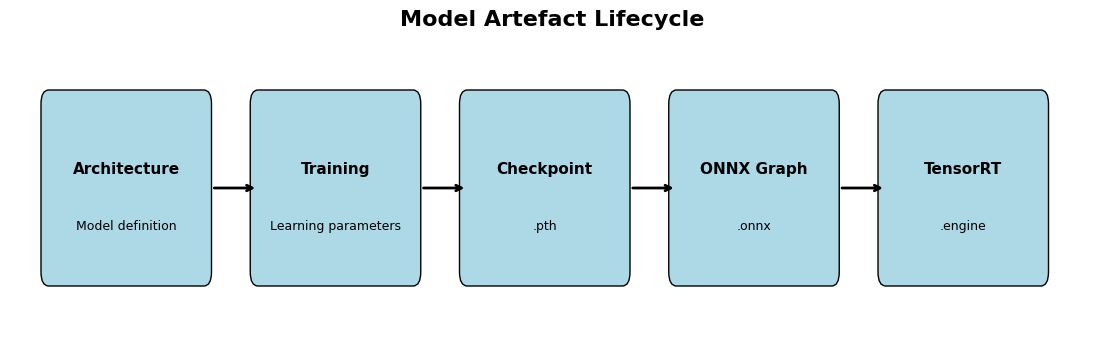

Lifecycle diagram saved: /content/skill7_model_artifacts/reports/model_lifecycle.png


In [13]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 4))

stages = [
    ("Architecture", "Model definition"),
    ("Training", "Learning parameters"),
    ("Checkpoint", ".pth"),
    ("ONNX Graph", ".onnx"),
    ("TensorRT", ".engine")
]

positions = [0.5, 3.2, 5.9, 8.6, 11.3]

for i, (title, subtitle) in enumerate(stages):
    x = positions[i]

    box = FancyBboxPatch(
        (x, 1.3), 2.0, 1.2,
        boxstyle="round,pad=0.1",
        edgecolor="black",
        facecolor="lightblue"
    )

    ax.add_patch(box)
    ax.text(x + 1, 2.0, title, ha="center",
            fontsize=11, weight="bold")
    ax.text(x + 1, 1.6, subtitle, ha="center", fontsize=9)

    if i < len(stages) - 1:
        ax.annotate(
            "",
            xy=(positions[i+1], 1.9),
            xytext=(x+2.1, 1.9),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

ax.set_xlim(0, 14)
ax.set_ylim(0.8, 3)
ax.axis("off")
ax.set_title("Model Artefact Lifecycle", fontsize=16, weight="bold")

diagram_path = os.path.join(
    base_path,
    "reports",
    "model_lifecycle.png"
)

plt.savefig(diagram_path, dpi=300, bbox_inches="tight")
plt.show()

print("Lifecycle diagram saved:", diagram_path)


In [14]:

import os
from datetime import datetime

# Define expected artefacts
artefacts = {
    "Model Checkpoint (.pth)": os.path.join(
        base_path, "checkpoints", "traffic_cnn_checkpoint.pth"
    ),
    "ONNX Graph (.onnx)": os.path.join(
        base_path, "onnx", "traffic_cnn.onnx"
    ),
    "TensorRT Documentation": os.path.join(
        base_path, "tensorrt", "tensorrt_stage.txt"
    ),
    "Lifecycle Diagram": os.path.join(
        base_path, "reports", "model_lifecycle.png"
    )
}

# Generate report
report = []
report.append("SKILL 7 - MODEL ARTEFACT LIFECYCLE AUDIT")
report.append("=" * 50)
report.append("Date: " + datetime.now().strftime("%d-%m-%Y %H:%M"))
report.append("")

for name, path in artefacts.items():
    if os.path.exists(path):
        size = os.path.getsize(path) / 1024
        status = f"CREATED ({size:.2f} KB)"
    else:
        status = "NOT FOUND"

    report.append(f"{name}: {status}")

report.append("")
report.append("TensorRT engine (.engine): NOT GENERATED")
report.append("Reason: TensorRT unavailable in current Colab environment.")
report.append("")
report.append("Audit completed.")

# Save report
report_path = os.path.join(
    base_path, "reports", "final_audit_report.txt"
)

with open(report_path, "w") as f:
    f.write("\n".join(report))

print("\n".join(report))
print("\nFinal report saved at:", report_path)


SKILL 7 - MODEL ARTEFACT LIFECYCLE AUDIT
Date: 24-11-2026 02:55

Model Checkpoint (.pth): CREATED (75575.65 KB)
ONNX Graph (.onnx): CREATED (3.68 KB)
TensorRT Documentation: CREATED (0.69 KB)
Lifecycle Diagram: CREATED (89.79 KB)

TensorRT engine (.engine): NOT GENERATED
Reason: TensorRT unavailable in current Colab environment.

Audit completed.

Final report saved at: /content/skill7_model_artifacts/reports/final_audit_report.txt
